# Day 3: Housing market regimes (unsupervised learning)

**Group 8:** Akshat Dayal, Bhavini Manot, Bo De Roeck
**Course:** AI Methods I – Day 3 (IAAC MaAI 2026/27)
**Outputs:** [dataset on Hugging Face](https://huggingface.co/datasets/iaac-maai/day3-group8-housing-market-regimes) · [model on Hugging Face](https://huggingface.co/iaac-maai/day3-group8-market-regimes)

### Where to find each requirement

| Brief section | In this notebook |
|---|---|
| 0. Introduction, use case, unit of analysis | Section 0 |
| 1. Features, scaling, skewed and categorical columns | Section 1 |
| 2. PCA (explained variance, loadings) and t-SNE | Section 2 |
| 3. K-Means + hierarchical + DBSCAN, choice of k / eps, ARI comparison | Section 3 |
| 4. Stability (random starts and 80 % subsamples) | Section 4 |
| 5. Profiles, cross-tabs, cluster names, clusters on the maps | Section 5 |
| 6. Save, reload and predict one example | Section 6 |
| 7. Export the clustered dataset | Section 7 |
| 8. Conclusions and limitations | Section 8 |

## 0. Introduction and problem definition

**Question:** which typical *phases* (regimes) does a national housing market go through, and in which phase was each country in each year?

- **Who uses the groups, and for what?** A housing policy analyst (ministry, central bank, OECD/IMF) who follows many countries and wants a shared vocabulary of market phases, e.g. "Spain and Ireland were in the same kind of boom in 2006".
- **What defines "similar"?** How the market **moves** (price growth, income growth, momentum) and whether it is expensive **compared with its own history**. Not the country or the year.
- **What makes a cluster useful?** It can be named, it is stable, and it suggests an action (e.g. cool down lending in a boom).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"         # the clustered dataset we publish
for folder in [FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### Load the data

We use the cleaned, model-ready dataset made by our Day 1 notebook in [Group8-day1-assignment](https://github.com/iaac-maai/Group8-day1-assignment) (the same file as on Day 2). It is small (≈ 0.2 MB), so a copy is committed in `data/`. We rebuild readable `country` and `region` columns (Day 1 stored the region as one-hot columns) and drop the columns that have the same value in every row.

In [2]:
raw = pd.read_csv(DATA_DIR / "housing_affordability_model_ready.csv")

COUNTRY_NAMES = {
    "AUS": "Australia", "BEL": "Belgium", "CAN": "Canada", "CHE": "Switzerland", "COL": "Colombia",
    "DEU": "Germany", "DNK": "Denmark", "ESP": "Spain", "FIN": "Finland", "FRA": "France",
    "GBR": "United Kingdom", "HRV": "Croatia", "IRL": "Ireland", "ISR": "Israel", "ITA": "Italy",
    "JPN": "Japan", "KOR": "South Korea", "LUX": "Luxembourg", "NLD": "Netherlands", "NOR": "Norway",
    "NZL": "New Zealand", "PRT": "Portugal", "SVN": "Slovenia", "SWE": "Sweden",
    "USA": "United States", "ZAF": "South Africa",
}
region_cols = [c for c in raw.columns if c.startswith("region_")]
constant_cols = [c for c in raw.columns if raw[c].nunique() == 1]

df = raw.drop(columns=constant_cols + region_cols).copy()
df.insert(0, "country", df["iso"].map(COUNTRY_NAMES))
df.insert(2, "region", raw[region_cols].idxmax(axis=1).str.replace("region_", ""))
df = df.sort_values(["iso", "year"]).reset_index(drop=True)

print(df.shape, "|", df["iso"].nunique(), "countries |", df["year"].min(), "-", df["year"].max())
df[["country", "region", "year", "affordability", "real_hpi_change_pct", "real_income_change_pct"]].head()

(1210, 17) | 26 countries | 1977 - 2024


,country,region,year,affordability,real_hpi_change_pct,real_income_change_pct
0,Australia,Oceania,1977,39.048834,-1.016166,-0.290698
1,Australia,Oceania,1978,38.061170,-0.699953,1.876822
2,Australia,Oceania,1979,38.880944,2.208647,0.053658
3,Australia,Oceania,1980,42.938456,10.988506,0.500536
4,Australia,Oceania,1981,44.351318,5.219553,1.867663


**Unit of analysis: one row = one country in one year** (1,210 rows). The data is already yearly, so no aggregation is needed. We cluster country-years, not countries: 26 countries would be too few rows, and our user wants to know the phase of a market in a given year.

## 1. Features and preprocessing

### Features we cluster on

The price and income columns are **indexes**: their level cannot be compared between countries. So we only use measures that are comparable:

| Feature | How it is made | Meaning |
|---|---|---|
| `log_afford_vs_own_avg` | log(affordability ÷ the country's own average) | Is housing expensive *for this country*? 0 = normal |
| `afford_momentum_pct` | affordability ÷ its 3-year average − 1 (%) | Is affordability getting worse (+) or better (−)? |
| `real_hpi_change_pct` | from Day 1 | Real house price growth this year (%) |
| `real_income_change_pct` | from Day 1 | Real income growth this year (%) |

**Kept aside for interpretation:** `country`, `region`, `year`/`decade`, `gfc_period` (2007–2010), the raw `affordability` level and `affordability_next` (next year). We leave them out on purpose so we can use them afterwards to **check** whether the clusters match real history.

In [3]:
country_avg = df.groupby("iso")["affordability"].transform("mean")
df["afford_vs_own_avg_pct"] = (df["affordability"] / country_avg - 1) * 100   # readable version, for profiles
df["log_afford_vs_own_avg"] = np.log(df["affordability"] / country_avg)
df["afford_momentum_pct"] = (df["affordability"] / df["affordability_3yr_avg"] - 1) * 100

FEATURES = ["log_afford_vs_own_avg", "afford_momentum_pct", "real_hpi_change_pct", "real_income_change_pct"]
X = df[FEATURES]
X.describe().round(2)

,log_afford_vs_own_avg,afford_momentum_pct,real_hpi_change_pct,real_income_change_pct
count,1210.00,1210.00,1210.00,1210.00
mean,-0.03,-0.03,1.74,1.62
std,0.26,5.67,6.79,2.95
min,-0.92,-31.85,-25.34,-15.90
25%,-0.21,-3.22,-2.21,0.13
50%,-0.02,-0.13,1.43,1.51
75%,0.14,3.32,5.64,2.89
max,0.91,23.77,30.65,42.58


### Skewed and categorical columns

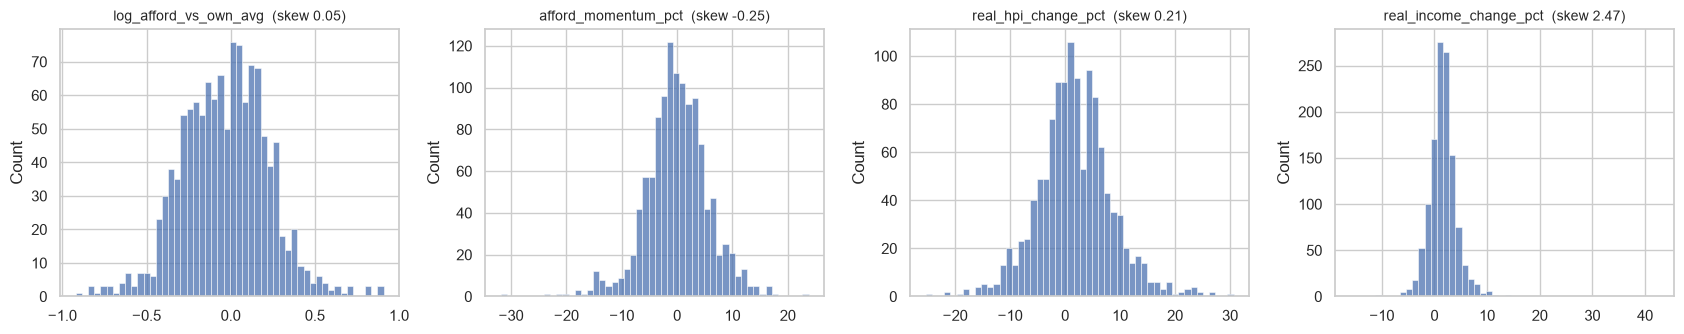

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, col in zip(axes, FEATURES):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(f"{col}  (skew {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
save_fig("01_feature_distributions")
plt.show()

- **Skew:** the ratio "affordability ÷ the country's average" is skewed (from 0.4× to 2.5× the usual level, skew 1.18), so we take its **log**: the skew drops to 0.05. The growth rates have long tails (booms and crashes of ±25–30 %; income growth is the most skewed, 2.47, because of a few fast-growth years in South Korea, Israel and Croatia). These are real events, not errors, so we **keep** them.
- **Categorical columns:** country and region are not clustered on (they are kept aside), so no one-hot encoding is needed.
- **Scaling:** the features have different units and spreads (a log ratio vs percentages). Without scaling, price growth would dominate the distances. We use a `StandardScaler` (and later put it inside a `Pipeline` with the model).

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 2. Dimensionality reduction

### 2.1 PCA: explained variance

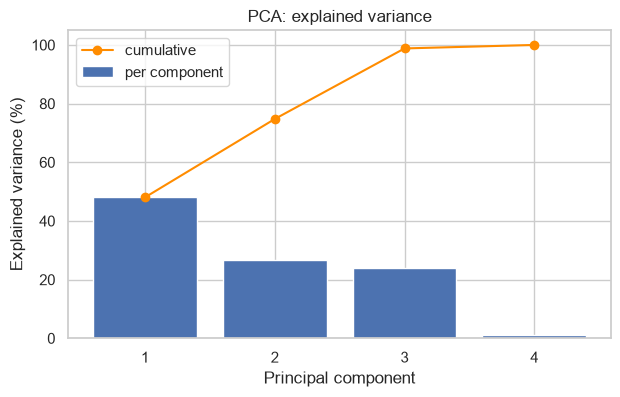

Explained variance (%): [48.  26.7 24.1  1.2]


In [6]:
pca = PCA().fit(X_scaled)
explained = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(7, 4))
plt.bar(range(1, 5), explained, label="per component")
plt.plot(range(1, 5), explained.cumsum(), "o-", color="darkorange", label="cumulative")
plt.xticks(range(1, 5))
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.title("PCA: explained variance")
plt.legend()
save_fig("02_pca_explained_variance")
plt.show()

print("Explained variance (%):", explained.round(1))

### 2.2 PCA: loadings

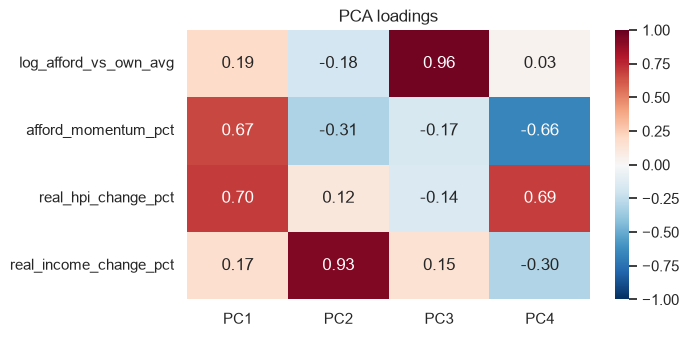

In [7]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])

plt.figure(figsize=(6.5, 3.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("PCA loadings")
save_fig("03_pca_loadings")
plt.show()

**Reading the loadings:**
- **PC1 (48 %) = boom vs bust:** price growth and momentum together. High = prices rising fast.
- **PC2 (27 %) = income growth.**
- **PC3 (24 %) = expensive vs cheap for the country** (`log_afford_vs_own_avg`).
- **PC4 (1 %)** is noise: momentum is almost a mix of price and income growth.

**How many real dimensions? Three.** They explain 99 % of the variance, and each one has a clear meaning. Since the variance is spread over three directions, a 2D picture will always hide part of the structure.

### 2.3 PCA and t-SNE maps

We keep the 2D coordinates of both maps: they become columns of the published dataset (section 7).

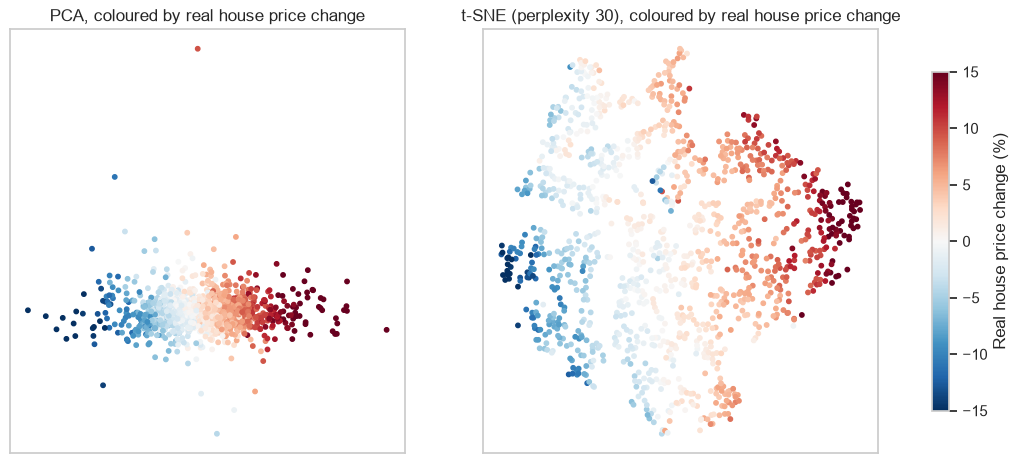

In [8]:
pca_coords = PCA(n_components=2).fit_transform(X_scaled)
tsne_coords = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, coords, title in [(axes[0], pca_coords, "PCA"), (axes[1], tsne_coords, "t-SNE (perplexity 30)")]:
    points = ax.scatter(coords[:, 0], coords[:, 1], c=df["real_hpi_change_pct"], cmap="RdBu_r", vmin=-15, vmax=15, s=10)
    ax.set_title(f"{title}, coloured by real house price change")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(points, ax=axes, label="Real house price change (%)", shrink=0.8)
save_fig("04_pca_tsne_maps")
plt.show()

**What the maps show:** one large cloud, with booms (red) on one side and crashes (blue) on the other, but **no empty gaps between groups**. Housing markets move gradually from one phase to another, so we expect clusters that *cut a continuum* rather than separate islands.

⚠️ On t-SNE, the size of the groups and the distances between them are not meaningful; only who is next to whom.

## 3. Clustering

We compare three algorithms: **K-Means**, **hierarchical clustering (Ward)** and **DBSCAN**.

### 3.1 K-Means: choosing k (elbow and silhouette)

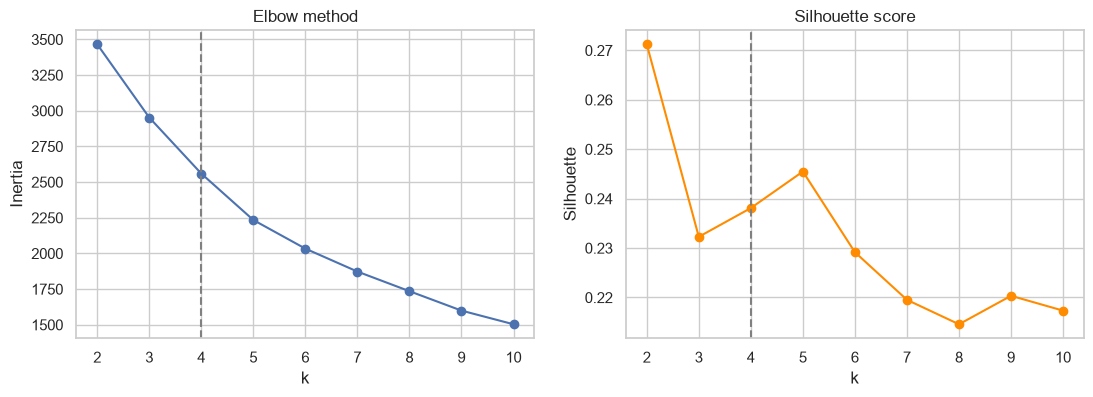

k,2,3,4,5,6,7,8,9,10
inertia,3466.022,2952.692,2559.818,2234.284,2033.712,1872.89,1735.399,1599.308,1503.547
silhouette,0.271,0.232,0.238,0.245,0.229,0.22,0.215,0.220,0.217


In [9]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_scaled, km.labels_)})
k_scan = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_scan.index, k_scan["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_scan.index, k_scan["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
for ax in axes:
    ax.axvline(4, color="grey", linestyle="--")
save_fig("05_choice_of_k")
plt.show()

k_scan.round(3).T

**No k stands out:** the elbow is gradual and the silhouette is low and flat (0.21–0.27) for every k. This is common with real data, so we chose with the use case: **k = 4**. Each of the four groups has a clear meaning (section 5). With k = 5 the extra group is only 31 extreme years; with k = 6 the new groups were hard to tell apart.

In [10]:
K = 4
kmeans_labels = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
print("K-Means cluster sizes:", np.bincount(kmeans_labels))

K-Means cluster sizes: [364 209 420 217]


### 3.2 Hierarchical clustering (Ward): dendrogram

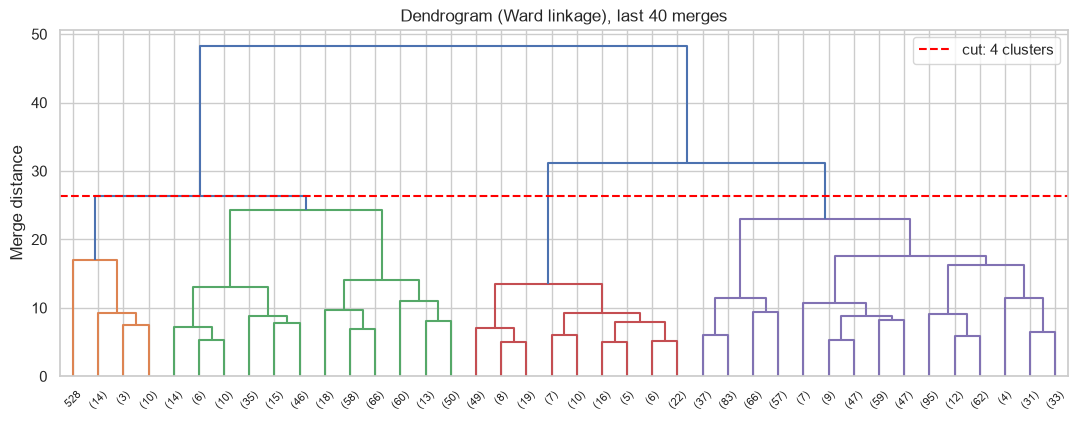

Ward cluster sizes: [391 649 142  28]


In [11]:
tree = linkage(X_scaled, method="ward")
cut = tree[-K + 1, 2] - 1e-9   # the height that gives 4 clusters

plt.figure(figsize=(13, 4.5))
dendrogram(tree, truncate_mode="lastp", p=40, color_threshold=cut)
plt.axhline(cut, color="red", linestyle="--", label="cut: 4 clusters")
plt.title("Dendrogram (Ward linkage), last 40 merges")
plt.ylabel("Merge distance")
plt.legend()
save_fig("06_dendrogram")
plt.show()

ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled)
print("Ward cluster sizes:", np.bincount(ward_labels))

The tallest merges are at the top (2 → 1 and 3 → 2 clusters); below 3–4 clusters the merges become similar in height, so there is no natural cut beyond that. Cutting at 4 clusters matches the K-Means choice. The Ward groups are very unequal (one of 649 rows, one of 28).

### 3.3 DBSCAN: k-distance plot

We use `min_samples = 2 × number of features = 8`, and read `eps` from the k-distance plot (distance of every point to its 8th neighbour, sorted).

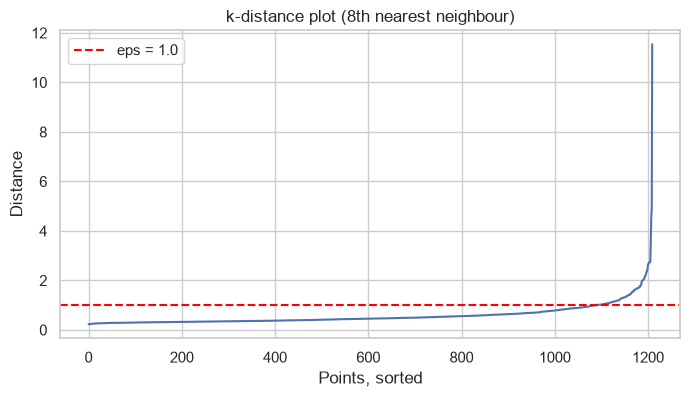

eps = 0.6: clusters = 1, noise points = 221
eps = 0.8: clusters = 1, noise points = 122
eps = 1.0: clusters = 1, noise points = 60
eps = 1.2: clusters = 1, noise points = 34


In [12]:
distances, _ = NearestNeighbors(n_neighbors=8).fit(X_scaled).kneighbors(X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(np.sort(distances[:, -1]))
plt.axhline(1.0, color="red", linestyle="--", label="eps = 1.0")
plt.title("k-distance plot (8th nearest neighbour)")
plt.xlabel("Points, sorted")
plt.ylabel("Distance")
plt.legend()
save_fig("07_k_distance")
plt.show()

for eps in [0.6, 0.8, 1.0, 1.2]:
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(X_scaled)
    print(f"eps = {eps}: clusters = {len(set(labels) - {-1})}, noise points = {(labels == -1).sum()}")

In [13]:
dbscan_labels = DBSCAN(eps=1.0, min_samples=8).fit_predict(X_scaled)
df["dbscan_outlier"] = (dbscan_labels == -1).astype(int)
df.loc[df["dbscan_outlier"] == 1, "country"].value_counts().head(5)

country
South Korea     17
Israel           8
Croatia          7
Luxembourg       4
South Africa     3
Name: count, dtype: int64

For every eps, DBSCAN finds **one dense cluster plus noise**: there are no empty spaces between regimes. So DBSCAN is not useful as the final model, but it works as an **outlier detector**: the 60 noise points (5 %) are mostly South Korea, Israel and Croatia in their early, unstable years. We keep them as the column `dbscan_outlier`.

### 3.4 Comparing the algorithms

In [14]:
comparison = pd.DataFrame({
    "clusters": [K, K, 1],
    "silhouette": [silhouette_score(X_scaled, kmeans_labels), silhouette_score(X_scaled, ward_labels), np.nan],
    "ARI vs K-Means": [1.0, adjusted_rand_score(kmeans_labels, ward_labels), adjusted_rand_score(kmeans_labels, dbscan_labels)],
}, index=["K-Means", "Ward", "DBSCAN"])
comparison.round(3)

,clusters,silhouette,ARI vs K-Means
K-Means,4,0.238,1.000
Ward,4,0.211,0.353
DBSCAN,1,NaN,0.008


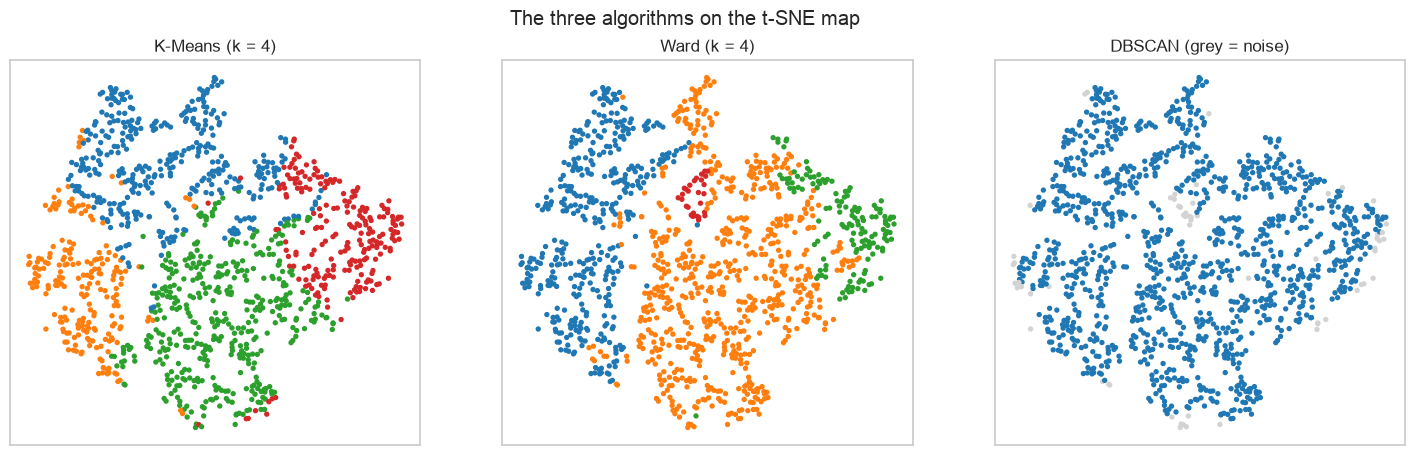

In [15]:
colors = {-1: "lightgrey", 0: "tab:blue", 1: "tab:orange", 2: "tab:green", 3: "tab:red"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, labels, title in [(axes[0], kmeans_labels, "K-Means (k = 4)"),
                          (axes[1], ward_labels, "Ward (k = 4)"),
                          (axes[2], dbscan_labels, "DBSCAN (grey = noise)")]:
    ax.scatter(tsne_coords[:, 0], tsne_coords[:, 1], c=[colors[l] for l in labels], s=8)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("The three algorithms on the t-SNE map")
save_fig("08_algorithms_compared")
plt.show()

**Do they agree?** Only partly: K-Means vs Ward has an **ARI of 0.35**. They agree on the extremes (booms, corrections) but draw the middle borders differently, which is expected when cutting a continuum. DBSCAN finds one cluster (ARI ≈ 0).

**Final choice: K-Means (k = 4).** It has the best silhouette, four balanced and nameable groups, it is stable (section 4), and it can assign new examples with `.predict()`. We keep the Ward labels as an extra column `cluster_ward`.

## 4. Stability

We re-run K-Means with 10 different `random_state` values, and on 10 random subsamples of 80 % of the rows, and compare each result with our final labels (adjusted Rand index: 1 = same groups).

In [16]:
seed_ari = [adjusted_rand_score(kmeans_labels, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X_scaled))
            for s in range(10)]

rng = np.random.default_rng(RANDOM_STATE)
subsample_ari = []
for _ in range(10):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    labels = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled[idx])
    subsample_ari.append(adjusted_rand_score(kmeans_labels[idx], labels))

rng = np.random.default_rng(RANDOM_STATE)
ward_ari = []
for _ in range(10):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled[idx])
    ward_ari.append(adjusted_rand_score(ward_labels[idx], labels))

stability = pd.DataFrame({"K-Means, random starts": seed_ari, "K-Means, 80 % subsamples": subsample_ari,
                          "Ward, 80 % subsamples": ward_ari})
stability.round(2).T

,0,1,2,3,4,5,6,7,8,9
"K-Means, random starts",0.98,0.94,0.97,0.99,0.93,0.97,0.93,0.97,0.93,0.98
"K-Means, 80 % subsamples",0.89,0.86,0.80,0.87,0.37,0.84,0.86,0.81,0.82,0.38
"Ward, 80 % subsamples",0.42,0.20,0.40,0.25,0.39,0.41,0.54,0.46,0.31,0.46


- **Random starts:** very stable (ARI 0.93–0.99).
- **80 % subsamples:** 8 out of 10 give the same groups (ARI 0.80–0.89), but 2 out of 10 cut the cloud differently (ARI ≈ 0.37). The booms and corrections are solid; the border between the two "middle" groups (affordable vs expensive) is the least certain.
- **Ward** is much less stable (ARI 0.20–0.54), which is another reason to choose K-Means.

## 5. Interpretation

### 5.1 Cluster profiles (size and median values)

In [17]:
df["cluster"] = kmeans_labels
df["cluster_ward"] = ward_labels

profile_cols = ["afford_vs_own_avg_pct", "afford_momentum_pct", "real_hpi_change_pct", "real_income_change_pct"]
profile = df.groupby("cluster")[profile_cols].median()
profile.insert(0, "share_%", df["cluster"].value_counts(normalize=True).sort_index() * 100)
profile.insert(0, "size", df["cluster"].value_counts().sort_index())
profile.round(1)

,size,share_%,afford_vs_own_avg_pct,afford_momentum_pct,real_hpi_change_pct,real_income_change_pct
cluster,,,,,,
0,364,30.1,-23.1,-0.7,1.3,1.8
1,209,17.3,-6.8,-6.3,-6.8,-0.1
2,420,34.7,14.5,0.3,1.5,1.4
3,217,17.9,1.6,6.9,10.1,2.5


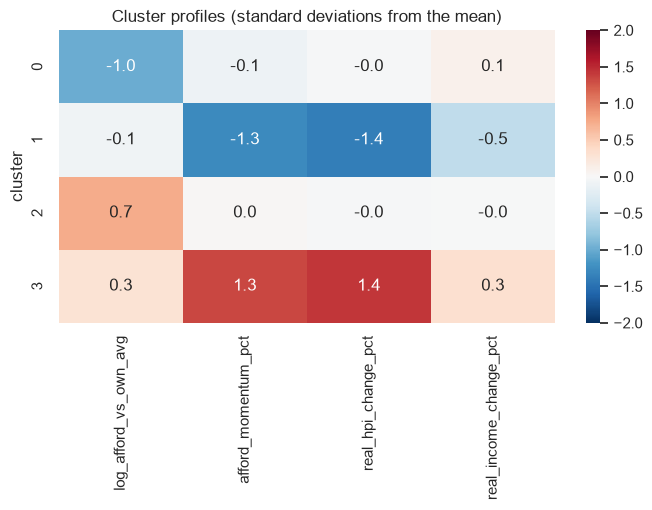

In [18]:
centroids = df.groupby("cluster")[FEATURES].mean()
centroids_z = (centroids - X.mean()) / X.std()   # in standard deviations from the overall mean

plt.figure(figsize=(8, 3.8))
sns.heatmap(centroids_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2)
plt.title("Cluster profiles (standard deviations from the mean)")
save_fig("09_cluster_profiles")
plt.show()

### 5.2 Cross-tabulations with variables we did *not* cluster on

In [19]:
df["afford_change_next_pct"] = (df["affordability_next"] / df["affordability"] - 1) * 100

next_year = df.groupby("cluster").agg(
    median_change_next_year_pct=("afford_change_next_pct", "median"),
    share_worse_next_year_pct=("afford_change_next_pct", lambda s: (s > 0).mean() * 100),
    share_in_2007_2010_crisis_pct=("gfc_period", lambda s: s.mean() * 100),
    median_year=("year", "median"),
)
next_year.round(1)

,median_change_next_year_pct,share_worse_next_year_pct,share_in_2007_2010_crisis_pct,median_year
cluster,,,,
0,0.8,57.4,7.4,1999.0
1,-4.6,15.3,17.7,1993.0
2,-0.4,47.1,14.5,2008.0
3,4.5,79.7,2.3,2002.0


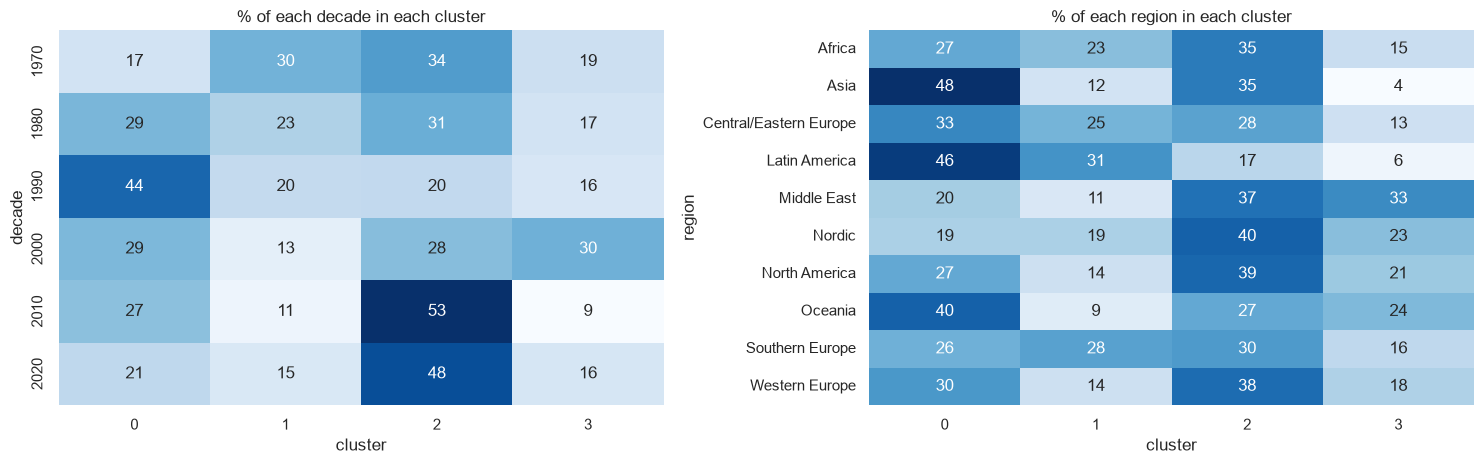

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(pd.crosstab(df["decade"], df["cluster"], normalize="index") * 100, annot=True, fmt=".0f",
            cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("% of each decade in each cluster")
sns.heatmap(pd.crosstab(df["region"], df["cluster"], normalize="index") * 100, annot=True, fmt=".0f",
            cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("% of each region in each cluster")
plt.tight_layout()
save_fig("10_crosstab_decade_region")
plt.show()

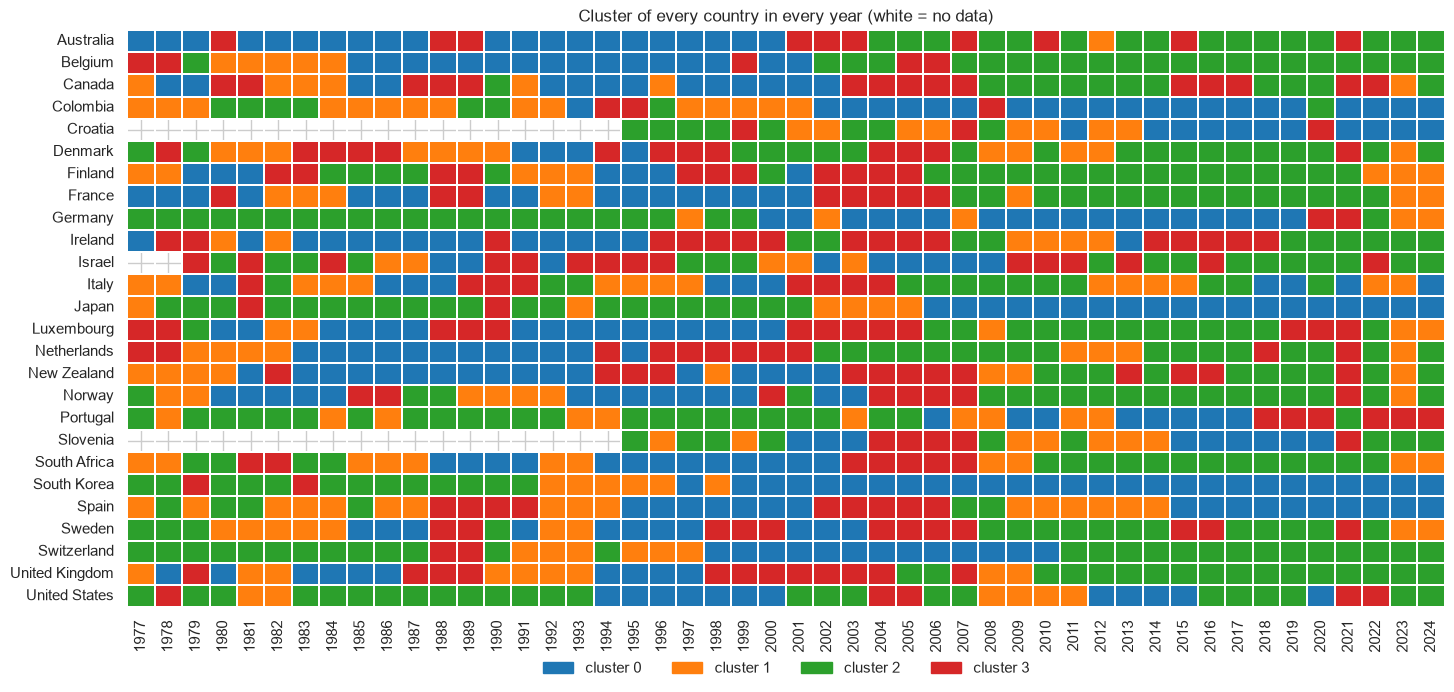

In [21]:
cluster_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
timeline = df.pivot(index="country", columns="year", values="cluster")

plt.figure(figsize=(17, 7.5))
sns.heatmap(timeline, cmap=cluster_colors, cbar=False, linewidths=0.3, linecolor="white")
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cluster_colors],
           labels=[f"cluster {i}" for i in range(K)], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=K, frameon=False)
plt.title("Cluster of every country in every year (white = no data)")
plt.xlabel("")
plt.ylabel("")
save_fig("11_timeline_country_year")
plt.show()

**What the cross-tabs show:**
- **Next year:** after a cluster 3 year, affordability gets worse again in **80 %** of cases; after a cluster 1 year it keeps improving in **85 %** of cases.
- **Decades:** cluster 2 dominates the 2010s (53 %) and 2020s (48 %); cluster 3 peaks in the 2000s, before the 2008 crisis; cluster 1 is over-represented in the 2007–2010 crisis years.
- **Known episodes** appear in the timeline: Spain and Ireland go 3 → 2 → 1 between 2005 and 2012 (the USA one year earlier); Finland and Sweden do the same around their 1990 banking crises.
- **Regions** matter less than time: every region goes through every cluster.

### 5.3 Naming the clusters

| Cluster | Name | Justification |
|---|---|---|
| 0 | **affordable steady growth** | Housing 23 % cheaper than the country's average; prices (+1.3 %) and incomes (+1.8 %) grow slowly and together; no momentum. Peaks in the 1990s. |
| 1 | **price correction** | Real prices fall (−6.8 %/yr), incomes flat; affordability improves fast and keeps improving next year (85 %). Over-represented in crisis years. |
| 2 | **expensive plateau** | Housing 15 % more expensive than the country's average, but prices and incomes barely move. Comes after booms; the most common phase since 2010. |
| 3 | **price boom** | Real prices +10 %/yr, much faster than incomes (+2.5 %); affordability worsens fast and keeps worsening next year (80 %). Peaks in the 2000s. |

All four clusters could be named. The weakest border is between clusters 0 and 2 (see section 4).

In [22]:
CLUSTER_NAMES = {
    0: "affordable steady growth",
    1: "price correction",
    2: "expensive plateau",
    3: "price boom",
}
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df["cluster_name"].value_counts()

cluster_name
expensive plateau           420
affordable steady growth    364
price boom                  217
price correction            209
Name: count, dtype: int64

### 5.4 The named clusters on the PCA and t-SNE maps

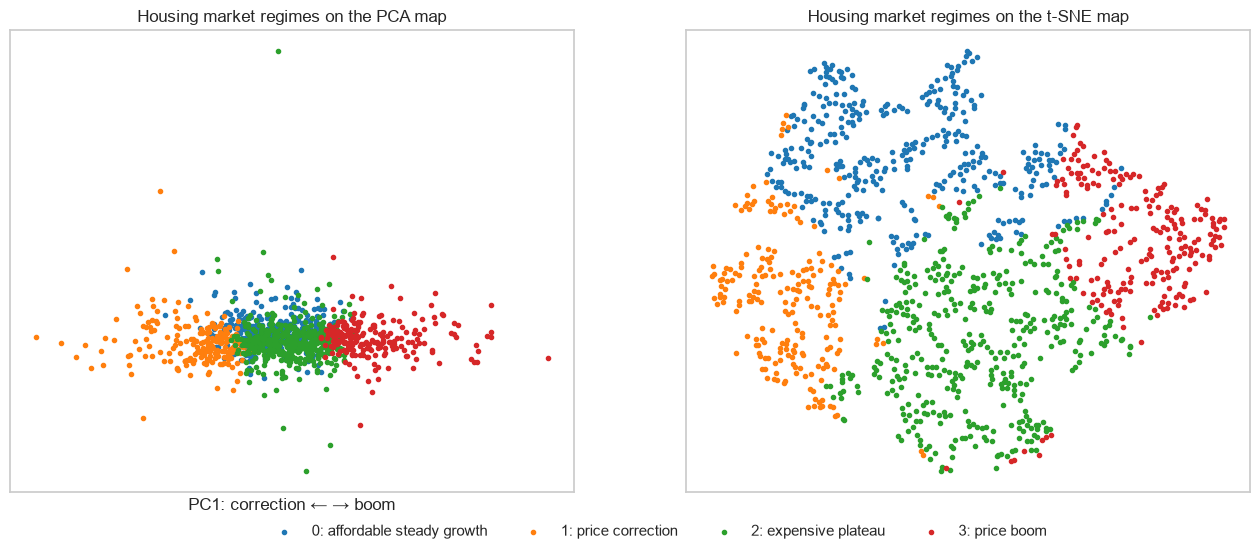

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, coords, title in [(axes[0], pca_coords, "PCA"), (axes[1], tsne_coords, "t-SNE")]:
    for cluster, name in CLUSTER_NAMES.items():
        mask = df["cluster"] == cluster
        ax.scatter(coords[mask, 0], coords[mask, 1], s=9, color=cluster_colors[cluster], label=f"{cluster}: {name}")
    ax.set_title(f"Housing market regimes on the {title} map")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].set_xlabel("PC1: correction ← → boom")
axes[1].legend(loc="upper center", bbox_to_anchor=(-0.05, -0.04), ncol=4, frameon=False)
save_fig("12_clusters_pca_tsne")
plt.show()

## 6. Save and reuse the model

The final model is a pipeline: `StandardScaler` + `KMeans(k=4)`. K-Means has `.predict()`, so no extra "assigner" is needed.

In [24]:
model = make_pipeline(StandardScaler(), KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE))
model.fit(df[FEATURES])
print("Same labels as the analysis:", (model.predict(df[FEATURES]) == df["cluster"]).all())

joblib.dump(model, MODEL_DIR / "model.joblib")

Same labels as the analysis: True


['../models/model.joblib']

**Reload and assign one hand-made example:** a market where real prices rose 9 % while incomes rose only 1 %, housing is 30 % more expensive than the country's usual level, and affordability is 5 % worse than its 3-year average.

In [25]:
reloaded = joblib.load(MODEL_DIR / "model.joblib")

new_market = pd.DataFrame([{
    "log_afford_vs_own_avg": np.log(1.30),
    "afford_momentum_pct": 5.0,
    "real_hpi_change_pct": 9.0,
    "real_income_change_pct": 1.0,
}])
cluster = reloaded.predict(new_market)[0]
print(f"Cluster {cluster}: {CLUSTER_NAMES[cluster]}")

Cluster 3: price boom


## 7. Export the clustered dataset (main deliverable)

The table contains the cleaned data, our engineered features, `cluster`, `cluster_name`, the extra labels `cluster_ward` and `dbscan_outlier`, and the map coordinates `pca_x`, `pca_y`, `tsne_x`, `tsne_y`.

In [26]:
final = df[["country", "iso", "region", "year", "decade",
            "affordability", "affordability_next", "real_house_price_index", "real_personal_disposable_income",
            "real_hpi_change_pct", "real_income_change_pct",
            "affordability_lag1", "affordability_lag2", "affordability_3yr_avg",
            "gfc_period", "hyperinflation_country", "price_shock_up",
            "afford_vs_own_avg_pct", "log_afford_vs_own_avg", "afford_momentum_pct", "afford_change_next_pct",
            "cluster", "cluster_name", "cluster_ward", "dbscan_outlier"]].copy()
final[["pca_x", "pca_y"]] = pca_coords
final[["tsne_x", "tsne_y"]] = tsne_coords

final.to_csv(DATASET_DIR / "housing_market_regimes.csv", index=False, float_format="%.4f")

# figures shown in the dataset card
for name in ["09_cluster_profiles", "11_timeline_country_year", "12_clusters_pca_tsne"]:
    (DATASET_DIR / f"{name}.png").write_bytes((FIG_DIR / f"{name}.png").read_bytes())

print(final.shape)
final.head()

(1210, 29)


,country,iso,region,year,decade,affordability,affordability_next,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,...,afford_momentum_pct,afford_change_next_pct,cluster,cluster_name,cluster_ward,dbscan_outlier,pca_x,pca_y,tsne_x,tsne_y
0,Australia,AUS,Oceania,1977,1970,39.048834,38.061170,21.43,54.88,-1.016166,...,-0.444529,-2.529305,0,affordable steady growth,0,0,-0.789593,-0.301614,-23.796822,25.400585
1,Australia,AUS,Oceania,1978,1970,38.061170,38.880944,21.28,55.91,-0.699953,...,-1.942138,2.153833,0,affordable steady growth,0,0,-0.826269,0.485440,-19.783867,29.202765
2,Australia,AUS,Oceania,1979,1970,38.880944,42.938456,21.75,55.94,2.208647,...,0.562013,10.435735,0,affordable steady growth,0,0,-0.321653,-0.189826,-16.535168,30.106314
3,Australia,AUS,Oceania,1980,1980,42.938456,44.351318,24.14,56.22,10.988506,...,7.453083,3.290436,3,price boom,2,0,1.494821,-0.344116,31.524925,15.242987
4,Australia,AUS,Oceania,1981,1980,44.351318,41.449879,25.40,57.27,5.219553,...,5.455495,-6.541947,0,affordable steady growth,1,0,0.768250,0.073269,2.180212,28.992369


## 8. Conclusions

### Key findings
- **Four housing market regimes:** affordable steady growth (364 country-years, 30 %), expensive plateau (420, 35 %), price boom (217, 18 %) and price correction (209, 17 %).
- **The main difference is boom vs bust** (PC1, 48 % of the variance): booms have real prices +10 %/yr vs +2.5 % for incomes; corrections have prices −6.8 %/yr.
- **The regimes have momentum:** after a boom year affordability worsens again in 80 % of cases; after a correction year it keeps improving in 85 %.
- **Markets often go boom → expensive plateau → correction**, as in Spain, Ireland and the USA around 2008, and Finland and Sweden around 1990.
- **The expensive plateau is today's most common regime:** about half of all country-years since 2010.

### Limitations and biases
- **No natural clusters:** silhouette ≈ 0.24 for every k and DBSCAN finds one cloud. The four regimes are a useful way to cut a continuum, and k = 4 was chosen for interpretability.
- **Stability:** 2 out of 10 subsamples gave a different cut; the border between clusters 0 and 2 is uncertain.
- **Hindsight:** "expensive for the country" is measured against the full 1977–2024 average, so this is a reading of history, not a real-time signal.
- **Data:** national averages of indexes (no cities, interest rates or rents), mostly high-income countries, unreliable early years for South Korea, Israel and Croatia.
- **Do not use** the clusters to forecast prices, for investment advice, or to rank countries by affordability.